# HeteroSpec MLSys 2027 figure audit

## tl;dr
Four main figures and one appendix inventory preserve the frozen scientific classes. Eleven verification microbenchmark cells were replayed; both M4 prompt-bootstrap CIs and all 180 358H paired observations reconcile. The 358H CPU/NPU means are 13.25/27.54 post-prefill seconds per request. The committed manuscript figures were directly compared with v0.2 and selected v0.3 assets; see comparison/OLD_NEW_COMPARISON.pdf.

This notebook is an audit companion. Final PDF/SVG figures are generated by `scripts/plot.py`, never from notebook screenshots.

## Context & Methods

Source commit: `1a11361f8526ec361e20dd6878d6e67352fb7bbd`. Authority: `PAPER_FRAMEWORK_HANDOFF.md`, the framework/mechanism notes, and frozen evidence.

### Key Assumptions
- Correctness means frozen generated-token equality, not functional HumanEval performance.
- Microbenchmark ranges are across contexts, not CIs or fully matched hardware comparisons.
- Phase-1 steady-state throughput differs from Phase-3 realized stateful costs.
- Arithmetic cost means and prompt-GM speedup are distinct estimands.
- Only repository evidence is used. Full source hashes are in `data/source_lock.json`.

In [1]:
from pathlib import Path
import json, subprocess, sys
import pandas as pd
from IPython.display import display, Image
HERE = Path.cwd()
assert (HERE / 'scripts/extract.py').is_file()
pd.set_option('display.max_columns', 8)
pd.set_option('display.width', 110)

## Data

### 1. Re-extract and check source fitness
The extractor rejects duplicate/missing selected rows and the historical header-only Phase-3 scaffold. It locks every consumed file with SHA256 and the Git blob identifier.

In [2]:
r = subprocess.run([sys.executable, 'scripts/extract.py'], check=True, capture_output=True, text=True)
print(r.stdout.strip())
quality = json.loads((HERE/'qa/data_quality.json').read_text())
print('Data-quality status:', quality['status'])
print('Pinned sources:', len(json.loads((HERE/'data/source_lock.json').read_text())))

PASS: extracted 11 micro cells, 2 M4 contrasts, 6 Phase-1 cells, 2 Phase-3 paths, 8 regimes
Data-quality status: PASS
Pinned sources: 40


### 2. Independent numerical and exported-vector validation
This pass does not import extraction or plotting helpers. It replays raw timing medians, campaign-specific bootstrap protocols and paired timing decompositions.

In [3]:
r = subprocess.run([sys.executable, 'scripts/validate.py', '--require-outputs'], check=True, capture_output=True, text=True)
print(r.stdout.strip())

Figure 1: NUMERICAL_PASS + vector/bounds checks
Figure 2: NUMERICAL_PASS + vector/bounds checks
Figure 3: NUMERICAL_PASS + vector/bounds checks
Figure 4: NUMERICAL_PASS + vector/bounds checks
Figure 5: NUMERICAL_PASS + vector/bounds checks


## Results

### Verification paths
All eleven cells remain inspectable. Fast and serialized B570 measurements are diagnostic; the formal failed-gate result is not replaced.

,path,context,v2_micro,repetitions,status
0,M4 Metal,512,1.022182,7,qualified
1,M4 Metal,2048,1.076126,7,qualified
2,M4 Metal,8192,1.032264,7,qualified
3,RTX batched,0,1.009030,20,blocked
4,RTX batched,256,0.983148,20,blocked
5,RTX serialized,0,2.430996,20,qualified
6,RTX serialized,256,2.137011,20,qualified
7,B570 fast,512,1.242576,20,diagnostic
8,B570 fast,2048,1.637295,20,diagnostic
9,B570 serialized,512,1.982668,20,diagnostic


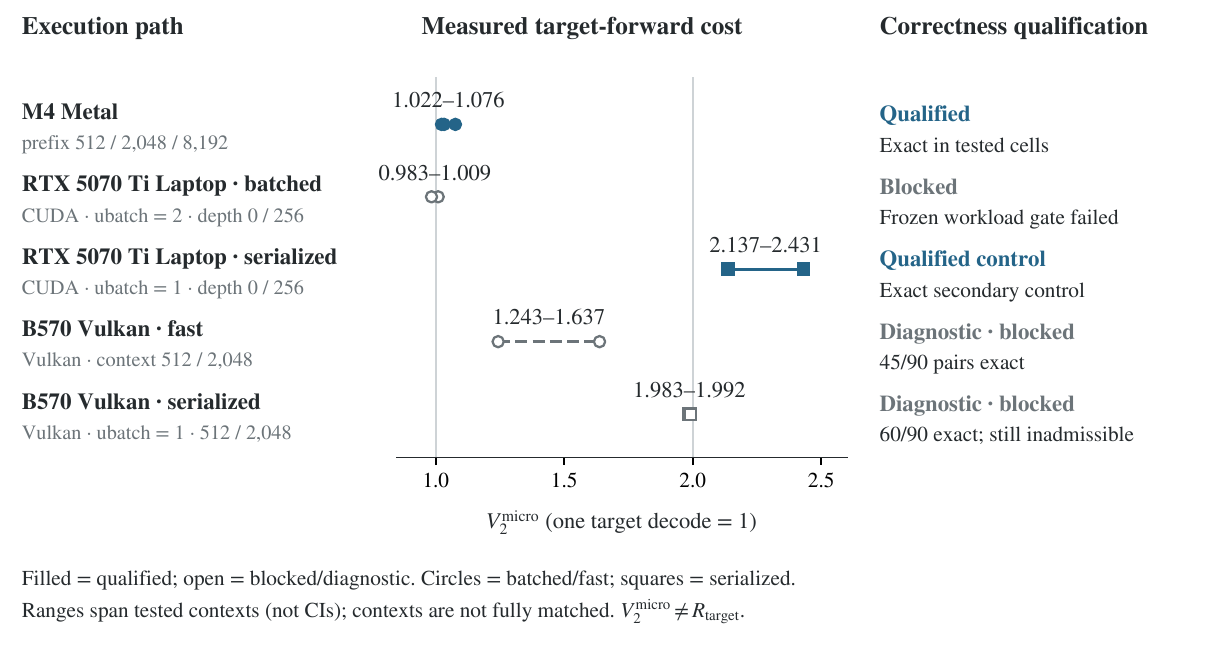

In [4]:
micro=pd.read_csv(HERE/'data/figure2_micro_cells.csv')
display(micro[['path','context','v2_micro','repetitions','status']].round(6))
display(Image(filename=str(HERE/'qa/figure2_180dpi.png'),width=810))

### M4 workload contrast
Two separately frozen studies. Their prompt-level bootstrap CIs do not provide a statistically paired between-workload contrast.

,workload,speedup,ci_low,ci_high,exact_pairs
0,Representative 24Q,0.841965,0.808693,0.876765,72
1,Preregistered HumanEval30,1.387352,1.350574,1.421625,90


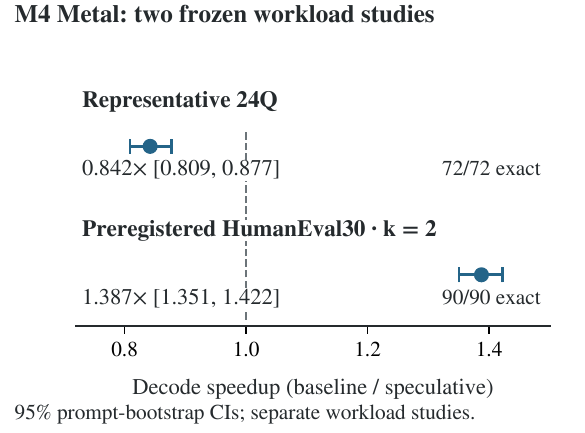

In [5]:
display(pd.read_csv(HERE/'data/figure3_workloads.csv')[['workload','speedup','ci_low','ci_high','exact_pairs']].round(6))
display(Image(filename=str(HERE/'qa/figure3_180dpi.png'),width=390))

### 358H isolated and realized boundaries
Five repetitions per isolated context/device cell. The Phase-1 CSV/JSON are checked against retained TPOT vectors; independently archived raw throughput arrays were unavailable in the repository snapshot. Phase-3 replay and proposal share one OpenVINO call and cannot be split retrospectively.

,device,context,tokens_s,ci_low,ci_high
0,CPU,512,89.86788,88.32671,90.31373
1,CPU,2048,64.84911,64.15094,65.76331
2,CPU,8192,30.80706,30.34303,31.36158
3,NPU,512,91.03623,90.76963,91.48958
4,NPU,2048,74.92645,72.40791,75.92358
5,NPU,8192,48.08303,47.10342,48.40382


,device,total_s,draft_s,target_s,residual_s,headline_speedup,aggregate_speedup
0,CPU,13.253126,1.673507,11.574811,0.004808,0.733915,0.722668
1,NPU,27.543780,16.071082,11.467641,0.005057,0.351663,0.347723


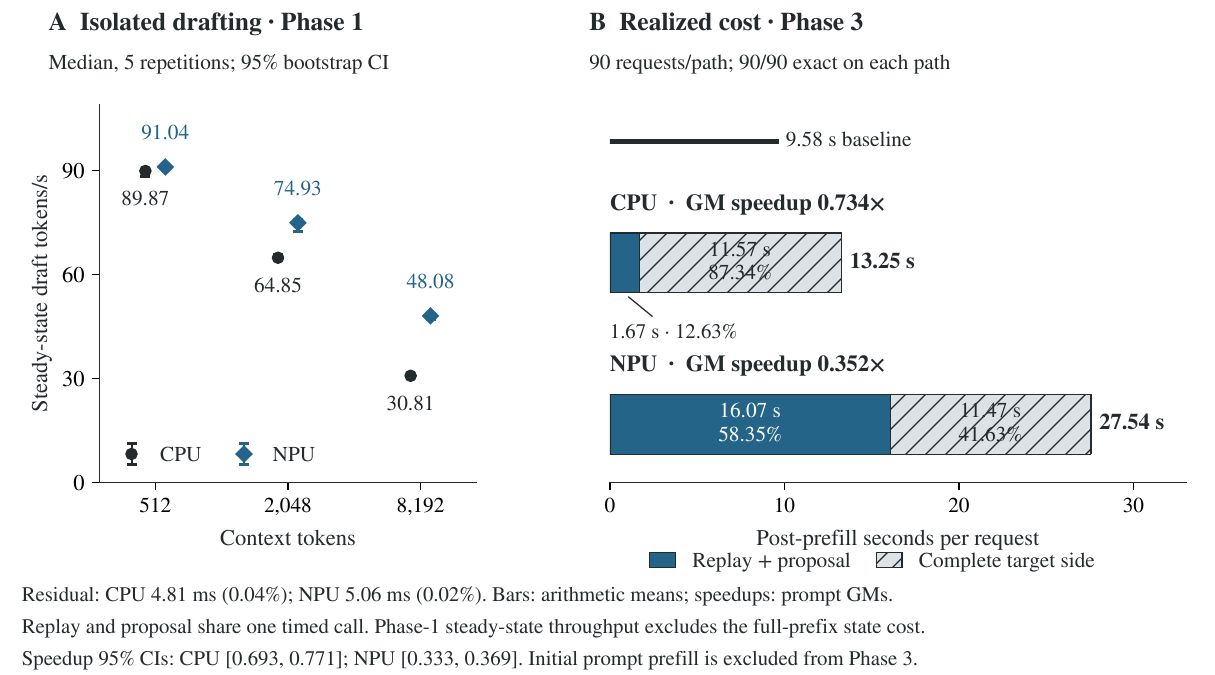

In [6]:
display(pd.read_csv(HERE/'data/figure4_isolated.csv')[['device','context','tokens_s','ci_low','ci_high']].round(5))
display(pd.read_csv(HERE/'data/figure4_realized.csv')[['device','total_s','draft_s','target_s','residual_s','headline_speedup','aggregate_speedup']].round(6))
display(Image(filename=str(HERE/'qa/figure4_180dpi.png'),width=810))

### Empirical overview and appendix inventory
Blocked paths have no admissible profitability coordinate. Row order is categorical and does not rank hardware. The overview presents heterogeneous local measurements and realized outcomes without a shared numerical axis.

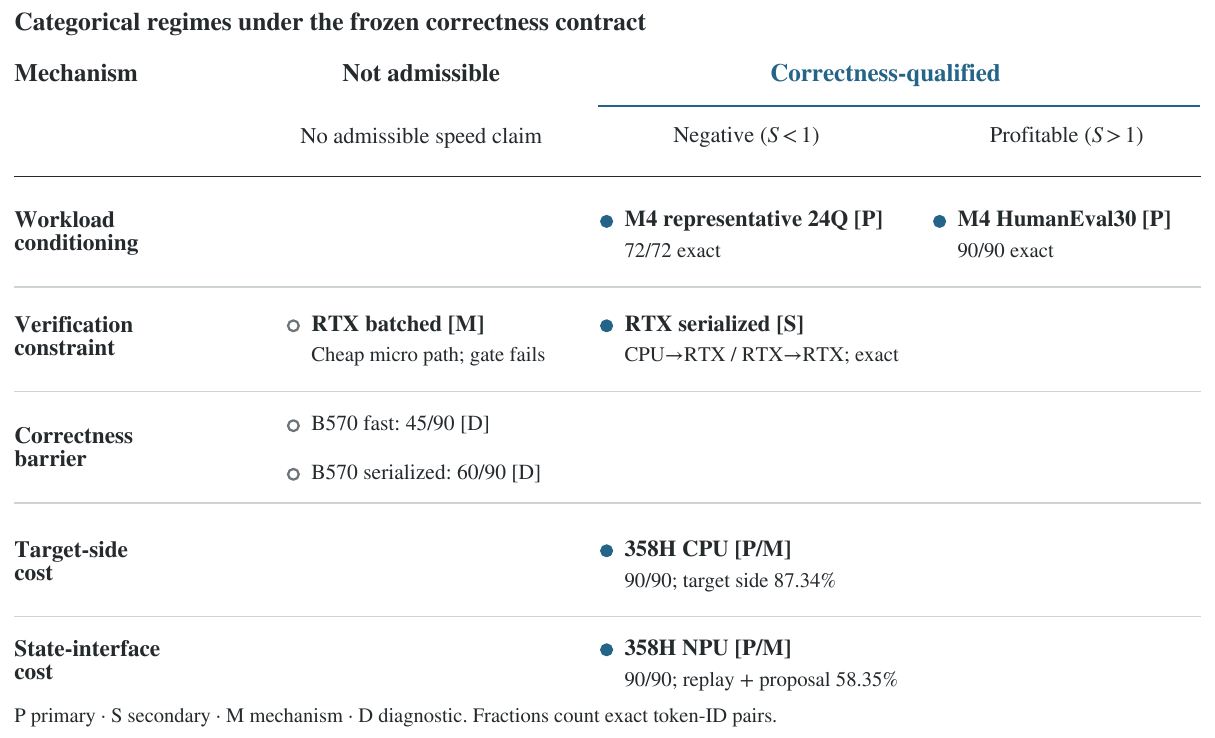

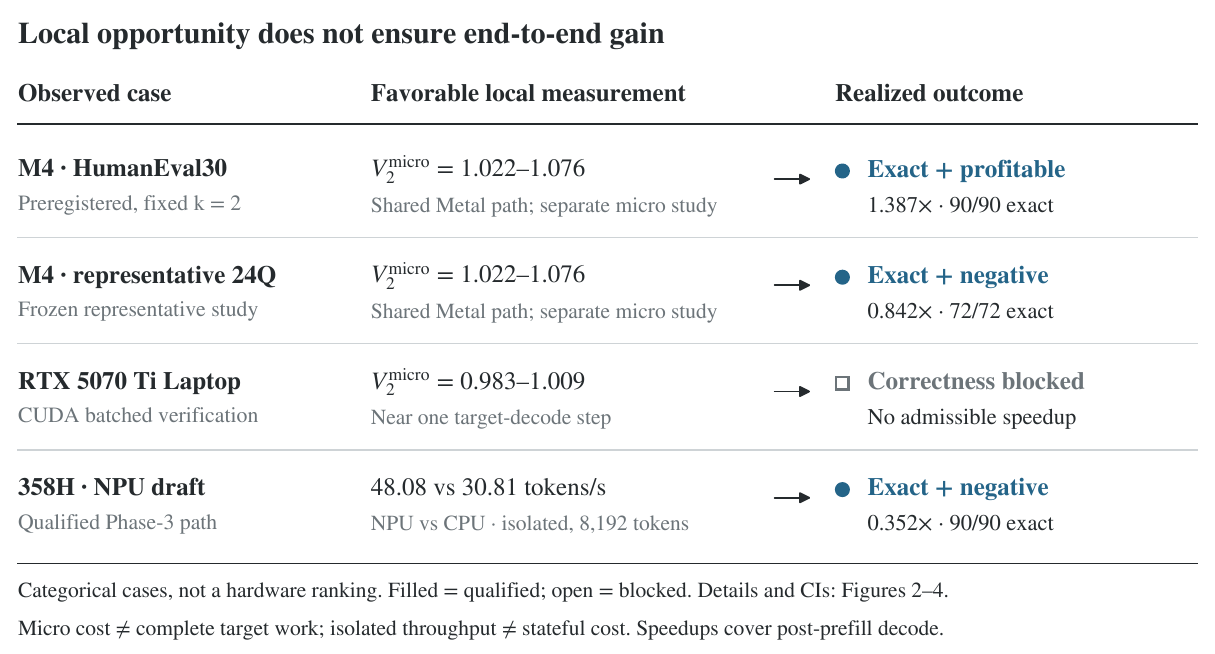

In [7]:
display(Image(filename=str(HERE/'qa/figure5_180dpi.png'),width=810))
display(Image(filename=str(HERE/'qa/figure1_180dpi.png'),width=810))

## Takeaways

- The cheapest physical target-forward path need not satisfy the frozen correctness contract.
- In this qualified adapter, isolated NPU throughput does not represent realized draft cost.
- B570 serialization improves observed exactness to 60/90 but remains inadmissible.
- Publication-candidate status applies to the new standalone assets at checked native widths.
- Actual OLD-versus-NEW selection is complete: redesign F1, take F2/F4, hybrid F3, appendix-only F5; see `FIGURE_REVIEW.md`.

Read `FIGURE_MANIFEST.md`, `qa/VISUAL_QA.md`, and `data/source_lock.json` for evidence classes, source boundaries and final SHA256 values.